# PSD PREDICTION ANALYSIS

In [1]:
import matplotlib.pyplot as plt  # type: ignore
import numpy as np  # type: ignore
import os
import pandas as pd  # type: ignore
from typing import Optional, cast, List, Union

import src.constants as cn
from src.psd_prediction_file_iterator import PSDPredictionFileIterator
from src.psd_prediction_analyzer import PSDPredictionAnalyzer
from src.nl_curve import NLCurve
from src.piecewise_system_discovery import PiecewiseSystemDiscovery
from src.biomodels_iterator import BiomodelsIterator
from src.timecourse_iterator import TimecourseIterator
from src.model import Model
from src.psd_prediction_analyzer import PSDPredictionAnalyzer

# Data analysis

In [2]:
def fileFilter(dct) -> bool:
    if not cn.COL_MAX_FRACTIONAL_REDUCTION in dct:
        return False
    if dct[cn.COL_MAX_FRACTIONAL_REDUCTION] !=  1e-5:
        pass
        #return False
    if dct[cn.COL_REPEAT] > 1:
        pass
        #return False
    return True



In [3]:
def dataframeFilter(df, dct) -> pd.DataFrame:
    new_df = df.copy()
    return new_df[ new_df [cn.COL_AGGREGATION_TYPE] == "model"]

In [4]:
df = PSDPredictionFileIterator.query()
#df = df [ df[cn.COL_SYSTEM_ID] == "BIOMD0000000297"]
df = df.reset_index()
df[[cn.COL_SYSTEM_ID, cn.COL_P50, cn.COL_AUC]]

,system_id,p50,auc
0,BIOMD0000000005,0.000000,0.000000
1,BIOMD0000000005,0.000000,0.095001
2,BIOMD0000000005,0.000000,0.126674
3,BIOMD0000000005,0.000000,0.142501
4,BIOMD0000000005,0.000000,0.158329
...,...,...,...
4555,BIOMD0000001056,0.980909,0.678178
4556,BIOMD0000001057,0.499610,0.127087
4557,BIOMD0000001058,0.995361,0.995941
4558,BIOMD0000001059,0.975921,0.916117


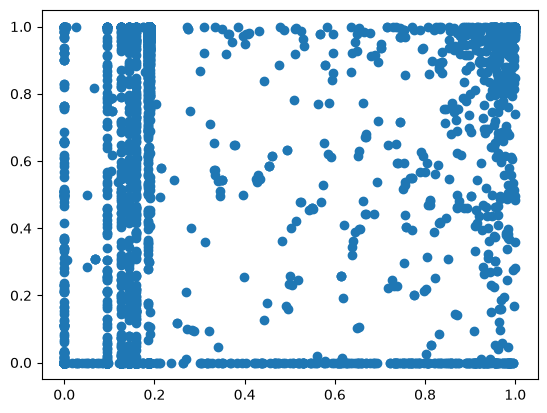

In [5]:
plt.scatter(df[cn.COL_AUC].values, df[cn.COL_P50].values)

In [6]:
#df.loc[df.groupby('A')['B'].idxmin(), ['A', 'B', 'C']]
df1 = df[df[cn.COL_P50] > 0.8]
mask = df1[cn.COL_AUC].isna()
df1 = df1[~mask]
dff = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),[cn.COL_SYSTEM_ID,
            cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_FILENAME, cn.COL_CHANGEPOINTS]]
dff

,system_id,num_changepoint,auc,p50,filename,changepoints
6,BIOMD0000000005,500,0.189622,0.987269,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."
14,BIOMD0000000010,500,0.189622,0.842129,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."
22,BIOMD0000000042,500,0.189622,0.994202,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."
29,BIOMD0000000234,50,0.186278,0.955787,piecewise_predictions__numpoint_100000__thresh...,"[196, 392, 588, 784, 980, 1176, 1373, 1569, 17..."
31,BIOMD0000000278,0,0.000000,0.999934,piecewise_predictions__numpoint_100000__thresh...,[]
...,...,...,...,...,...,...
3270,BIOMD0000001056,50,0.186278,0.962860,piecewise_predictions__numpoint_100000__thresh...,"[196, 392, 588, 784, 980, 1176, 1373, 1569, 17..."
3277,BIOMD0000001057,50,0.186278,0.927186,piecewise_predictions__numpoint_100000__thresh...,"[196, 392, 588, 784, 980, 1176, 1373, 1569, 17..."
3284,BIOMD0000001058,50,0.186278,0.897996,piecewise_predictions__numpoint_100000__thresh...,"[196, 392, 588, 784, 980, 1176, 1373, 1569, 17..."
3292,BIOMD0000001059,50,0.186278,0.958442,piecewise_predictions__numpoint_100000__thresh...,"[196, 392, 588, 784, 980, 1176, 1373, 1569, 17..."


# AUC and Model Accuracy

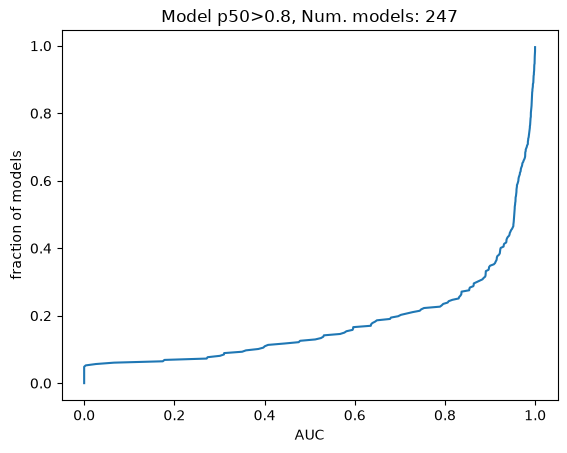

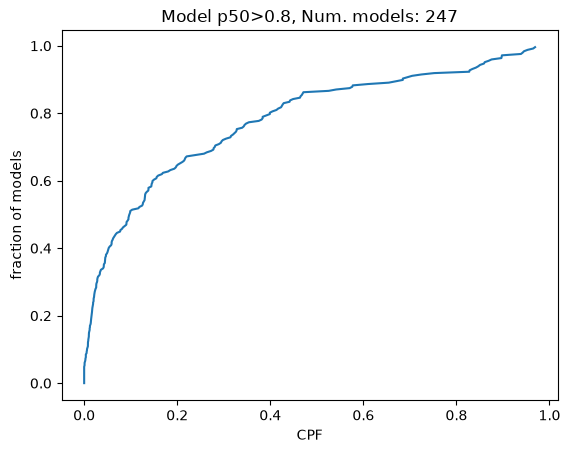

In [7]:
# Parameters
accuracy_threshold = 0.8
statistic = cn.COL_P50
#statistic = cn.COL_MIN

# Data construction
df = PSDPredictionFileIterator.query(file_filter=fileFilter, dataframe_filter=dataframeFilter,
        is_guard_filename=True)
mask = df[cn.COL_AUC].isna()
df = df[~mask]
df = df.reset_index()
df1 = df[df[statistic] > accuracy_threshold]
MODEL_DF = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),
    [cn.COL_SYSTEM_ID, cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_MAX, cn.COL_MIN, 
     cn.COL_FILENAME, cn.COL_CHANGEPOINTS]]
MODEL_DF["CPF"] = MODEL_DF[cn.COL_NUM_CHANGEPOINT] / 5000  # Account for lower max values
num_model = len(MODEL_DF[cn.COL_SYSTEM_ID].unique())
fraction_model = np.array(range(num_model))/num_model

sorted_auc = np.sort(MODEL_DF[cn.COL_AUC].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("AUC")
plt.ylabel("fraction of models")
plt.figure()


sorted_auc = np.sort(MODEL_DF["CPF"].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("CPF")
_ = plt.ylabel("fraction of models")

AUC indicates that there are 3 types of models
* Those that are well approximated by a single linear system
* Those that require a modest to significant number of piecewise approximations
* Those that require a very dense series of piecewise approximations

# AUC vs. Changepoints

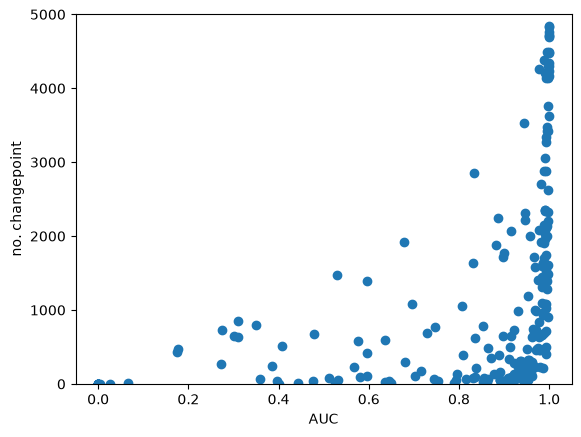

In [8]:
plt.scatter(MODEL_DF["auc"], MODEL_DF["num_changepoint"])
plt.ylim([0, 5000])
plt.xlabel("AUC")
_ = plt.ylabel("no. changepoint")

There are 10 coincident points at (0, 0)

Text(0.5, 0, 'num. changepoint')

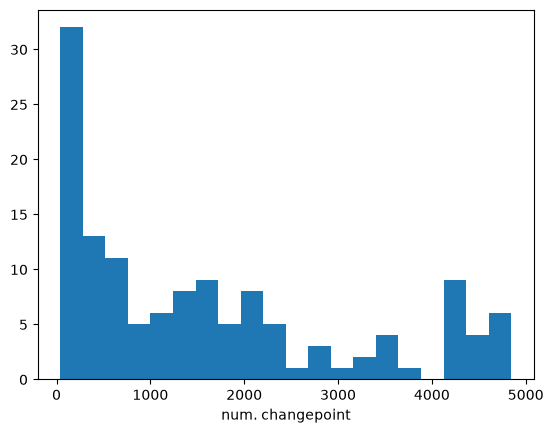

In [9]:
# Histogram of number of changepoints for high AUC models
ser = MODEL_DF[ (MODEL_DF["auc"] > 0.95) ] [ "num_changepoint"]
plt.hist(ser, bins = 20)
plt.xlabel("num. changepoint")

# Timecourse plots

In [10]:
MODEL_DF [ MODEL_DF[cn.COL_NUM_CHANGEPOINT] <= 10 ][[cn.COL_SYSTEM_ID, cn.COL_AUC, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]

,system_id,auc,p50,num_changepoint
4,BIOMD0000000278,0.000000,0.999934,0
69,BIOMD0000000666,0.003496,0.999727,5
79,BIOMD0000000677,0.000000,0.922101,0
123,BIOMD0000000736,0.000000,1.000000,0
130,BIOMD0000000745,0.000000,0.983569,0
183,BIOMD0000000799,0.000000,0.899953,0
189,BIOMD0000000807,0.000000,1.000000,0
209,BIOMD0000000830,0.000000,0.829780,0
228,BIOMD0000000851,0.000000,0.970465,0
672,BIOMD0000000883,0.026179,0.999714,4


# Illustration of the different model types

In [11]:
t_iter = TimecourseIterator(first_model_num=278, last_model_num=278)
item = list(t_iter)[0]
ser = MODEL_DF [MODEL_DF[cn.COL_SYSTEM_ID] == item.model_name].iloc[0]
ser

system_id                                            BIOMD0000000278
num_changepoint                                                    0
auc                                                              0.0
p50                                                         0.999934
max                                                         0.999978
min                                                         0.999918
filename           piecewise_predictions__numpoint_100000__thresh...
changepoints                                                      []
CPF                                                              0.0
Name: 4, dtype: object

In [12]:
mask = (MODEL_DF["auc"] > 0.3) & (MODEL_DF["auc"] < 0.6)
df = MODEL_DF[mask][[cn.COL_SYSTEM_ID, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]
MODEL_COLLECTION = [Model.getBiomodelNum(v) for v in df[cn.COL_SYSTEM_ID].values]
MODEL_COLLECTION = list(df[cn.COL_SYSTEM_ID].values)
MODEL_DF[mask][[cn.COL_SYSTEM_ID, cn.COL_AUC, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]

,system_id,auc,p50,num_changepoint
454,BIOMD0000000556,0.386094,1.000000,245
460,BIOMD0000000571,0.581460,0.999305,96
905,BIOMD0000000665,0.596562,0.862597,417
496,BIOMD0000000676,0.475717,0.884427,41
918,BIOMD0000000679,0.512393,0.917528,84
108,BIOMD0000000715,0.310355,0.922616,847
135,BIOMD0000000750,0.358696,0.917898,73
1000,BIOMD0000000775,0.478773,0.999266,672
171,BIOMD0000000786,0.407705,0.977081,516
627,BIOMD0000000828,0.309958,0.999978,632


Model 671 gets different accuracy than recorded.

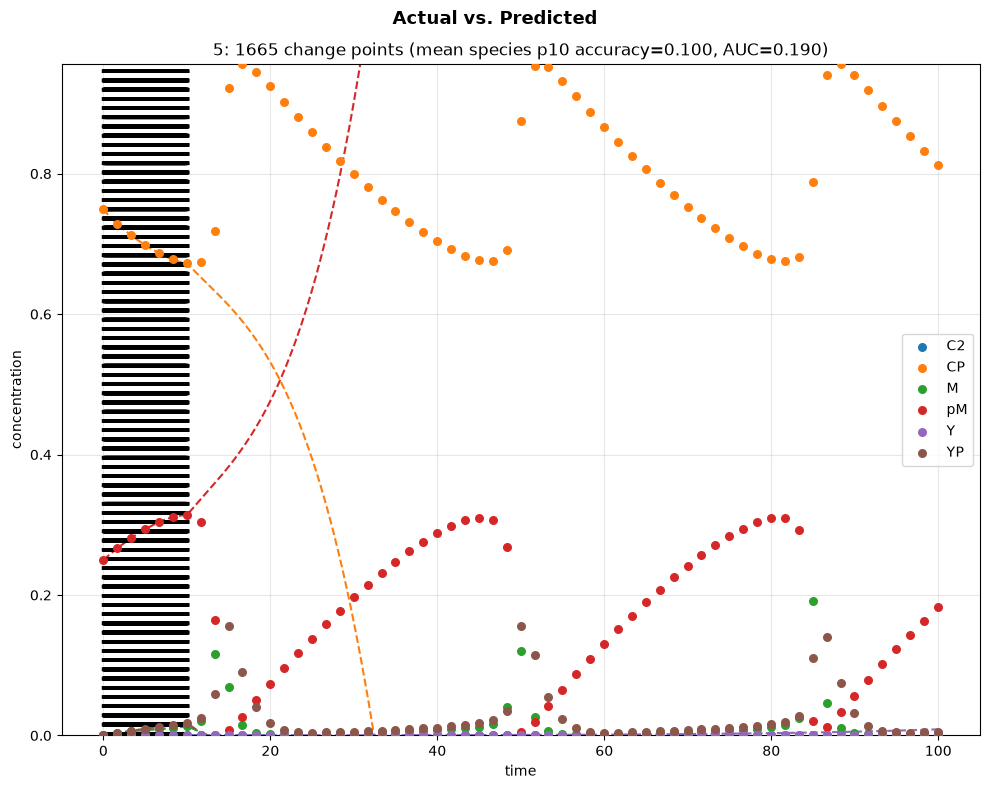

<Figure size 640x480 with 0 Axes>

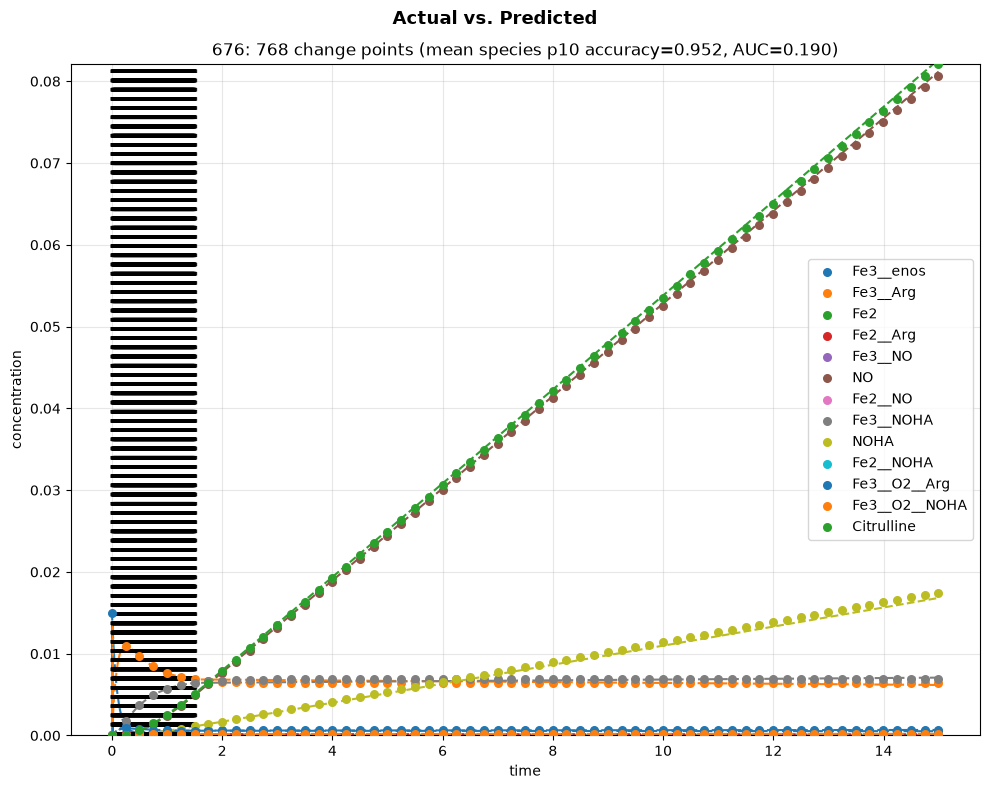

<Figure size 640x480 with 0 Axes>

In [13]:
def runner(model_collection):
    t_iter = TimecourseIterator(model_collection=model_collection)
    for item in t_iter:
        analyzer = PSDPredictionAnalyzer(item.model_name)
        try:
            psd = analyzer.makeBestPSD()
        except Exception as e:
            print(f"Could not process {item.model_name}: {e}")
            continue
        result = psd.plotPiecewise(legend=False, num_true_point=60, is_nochangepoint_plot=False)
        plt.savefig(f"changepoint_timecourse_{psd.model_num}.pdf")
        _ = plt.figure()

# Tests
runner([5, 676])